<a href="https://colab.research.google.com/github/AnirudhRajesh09/BIS/blob/main/BIS_Pgm4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 GACSM - ENERGY AWARE TASK SCHEDULING RESULTS

Optimized Task Allocation:


,Task,Processor,Voltage,Start Time,Finish Time,Duration,Energy
0,T0,CPU-3,0.85,0.000,29.412,29.412,12.644
1,T1,CPU-4,0.70,0.000,31.250,31.250,18.222
2,T2,CPU-2,0.70,31.412,58.884,27.473,12.250
3,T3,CPU-4,0.70,31.412,67.126,35.714,20.825
4,T4,CPU-1,0.70,33.250,54.679,21.429,7.350
5,T5,CPU-4,0.70,67.126,93.912,26.786,15.619
6,T6,CPU-2,0.70,69.126,91.104,21.978,9.800
7,T7,CPU-4,0.70,93.912,134.090,40.179,23.428
8,T8,CPU-3,0.85,93.104,129.869,36.765,15.805
9,T9,CPU-4,0.70,134.090,165.340,31.250,18.222



Total Energy: 322.2859
Makespan: 192.1261
Deadline: 255.0
Deadline Satisfied: True
Optimization Runtime: 2.2736 seconds
Schedule Valid: True


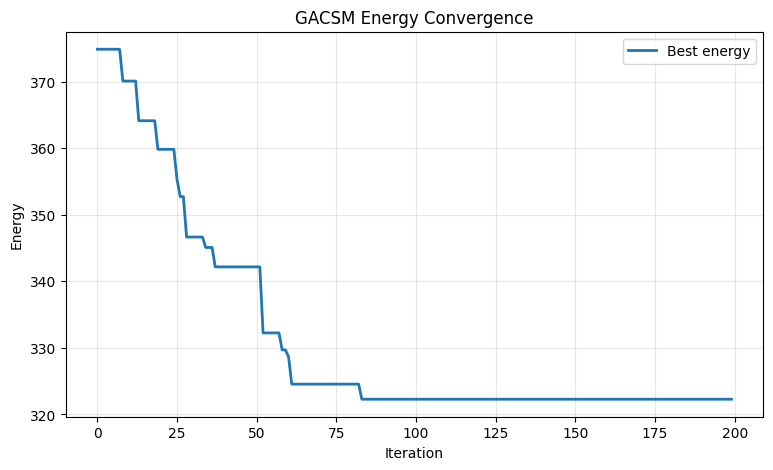

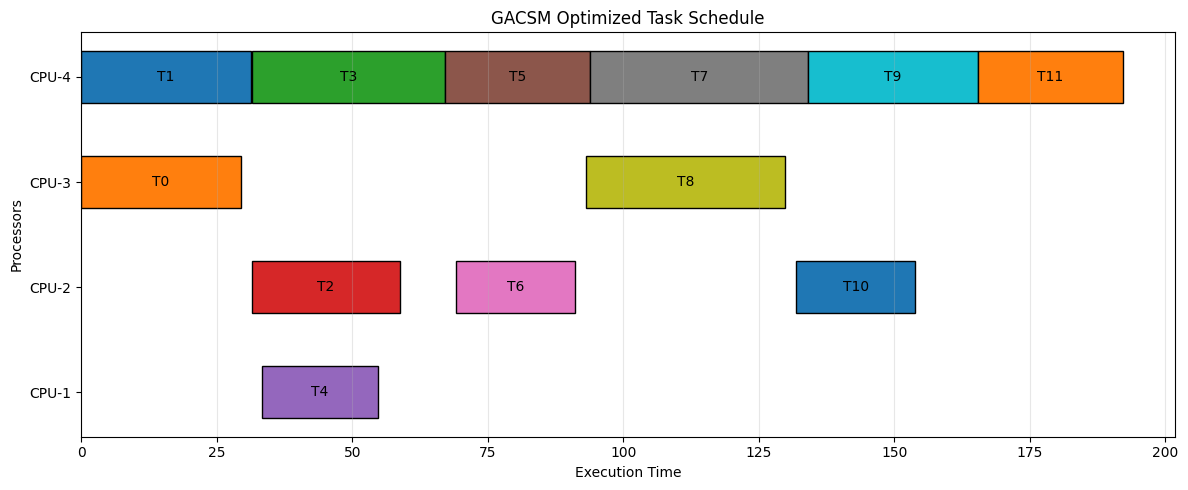

In [ ]:

# ================================================================
# GACSM: ENERGY-AWARE COMPUTER TASK SCHEDULING
# Based on Deng et al., IEEE Access, 2020
# DOI: 10.1109/ACCESS.2020.2970166
# ================================================================

import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import random
import math
import time

# Reproducibility
np.random.seed(42)
random.seed(42)

# ================================================================
# 1. TASK GRAPH (DAG)
# ================================================================

G = nx.DiGraph()

tasks = {
    0: 20, 1: 35, 2: 25, 3: 40,
    4: 15, 5: 30, 6: 20, 7: 45,
    8: 25, 9: 35, 10: 20, 11: 30
}

for task, workload in tasks.items():
    G.add_node(task, workload=workload)

dependencies = [
    (0, 2), (0, 3),
    (1, 3), (1, 4),
    (2, 5), (3, 5),
    (3, 6), (4, 6),
    (5, 7), (6, 7),
    (6, 8), (7, 9),
    (8, 9), (8, 10),
    (9, 11), (10, 11)
]

G.add_edges_from(dependencies)

assert nx.is_directed_acyclic_graph(G)

# Communication data
COMM_COST = 2.0

# ================================================================
# 2. HETEROGENEOUS PROCESSORS AND VOLTAGE LEVELS
# ================================================================

processors = [
    {"name": "CPU-1", "speed": 1.0, "power": 1.0,
     "voltages": [0.7, 0.85, 1.0]},
    {"name": "CPU-2", "speed": 1.3, "power": 1.3,
     "voltages": [0.7, 0.85, 1.0]},
    {"name": "CPU-3", "speed": 0.8, "power": 0.7,
     "voltages": [0.7, 0.85, 1.0]},
    {"name": "CPU-4", "speed": 1.6, "power": 1.7,
     "voltages": [0.7, 0.85, 1.0]}
]

RESOURCES = []

for p, processor in enumerate(processors):
    for v, voltage in enumerate(processor["voltages"]):
        RESOURCES.append({
            "processor": p,
            "voltage": voltage,
            "speed": processor["speed"] * voltage,
            "power": processor["power"] * voltage**3
        })

N = len(tasks)
R = len(RESOURCES)

# ================================================================
# 3. DOWNWARD-RANK / UPWARD-RANK PRIORITY
# ================================================================

# Average execution time across available resources
avg_execution = {
    t: G.nodes[t]["workload"] /
       np.mean([r["speed"] for r in RESOURCES])
    for t in G.nodes
}

rank = {}

for t in reversed(list(nx.topological_sort(G))):
    successors = list(G.successors(t))

    if successors:
        rank[t] = avg_execution[t] + max(
            COMM_COST + rank[s] for s in successors
        )
    else:
        rank[t] = avg_execution[t]

TASK_ORDER = sorted(G.nodes, key=lambda t: rank[t], reverse=True)

# ================================================================
# 4. SCHEDULING EVALUATOR
# ================================================================

def evaluate(solution, deadline=None):

    assignments = np.clip(
        np.rint(solution).astype(int), 0, R - 1
    )

    processor_available = np.zeros(len(processors))
    start_times = {}
    finish_times = {}
    schedule = {}

    for task in TASK_ORDER:

        resource = RESOURCES[assignments[task]]
        p = resource["processor"]

        predecessor_ready = 0.0

        for pred in G.predecessors(task):

            communication = (
                COMM_COST
                if RESOURCES[assignments[pred]]["processor"] != p
                else 0.0
            )

            predecessor_ready = max(
                predecessor_ready,
                finish_times[pred] + communication
            )

        start = max(
            predecessor_ready,
            processor_available[p]
        )

        duration = (
            G.nodes[task]["workload"] / resource["speed"]
        )

        finish = start + duration

        start_times[task] = start
        finish_times[task] = finish
        processor_available[p] = finish

        schedule[task] = {
            "processor": p,
            "voltage": resource["voltage"],
            "start": start,
            "finish": finish,
            "duration": duration,
            "energy": resource["power"] * duration
        }

    makespan = max(finish_times.values())

    # Dynamic + idle energy model
    dynamic_energy = sum(
        item["energy"] for item in schedule.values()
    )

    idle_energy = 0.0

    for p, processor in enumerate(processors):

        used_time = sum(
            item["duration"]
            for item in schedule.values()
            if item["processor"] == p
        )

        idle_time = max(0, makespan - used_time)

        # Idle power at the lowest voltage
        idle_power = (
            processor["power"] * processor["voltages"][0]**3
        )

        idle_energy += idle_power * idle_time

    total_energy = dynamic_energy + idle_energy

    return total_energy, makespan, schedule


# ================================================================
# 5. FITNESS AND DEADLINE HANDLING
# ================================================================

def fitness(solution, deadline):

    energy, makespan, _ = evaluate(solution)

    # Feasible solutions always take priority.
    # Among feasible solutions, minimize energy.
    # Among infeasible solutions, prioritize makespan.
    if makespan <= deadline:
        return (0, energy, makespan)

    return (1, makespan, energy)


def better(a, b, deadline):
    return fitness(a, deadline) < fitness(b, deadline)


# ================================================================
# 6. SINUSOIDAL CHAOTIC INITIALIZATION
# ================================================================

def chaotic_initialization(population, dimensions):

    population_data = np.zeros((population, dimensions))

    for i in range(population):

        x = np.random.uniform(0.1, 0.9)

        for j in range(dimensions):

            x = np.sin(np.pi * x)

            population_data[i, j] = (
                0.5 + x * (R - 1)
            )

    return population_data


# ================================================================
# 7. LEVY FLIGHT (MANTEGNA METHOD)
# ================================================================

def levy_flight(dimensions, beta=1.5):

    sigma = (
        math.gamma(1 + beta)
        * math.sin(math.pi * beta / 2)
        / (
            math.gamma((1 + beta) / 2)
            * beta
            * 2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = np.random.normal(0, sigma, dimensions)
    v = np.random.normal(0, 1, dimensions)

    return u / (np.abs(v) ** (1 / beta) + 1e-12)


# ================================================================
# 8. GAUSSIAN RANDOM WALK
# ================================================================

def gaussian_walk(solution, best, generation, max_iter):

    progress = generation / max_iter

    sigma = 0.5 * (1 - progress) + 0.01

    return (
        best
        + np.random.normal(0, sigma, len(solution))
        + np.random.random() * (best - solution)
    )


# ================================================================
# 9. COST-TO-TIME MODIFICATION STRATEGY
# ================================================================

def modification_strategy(solution, deadline):

    solution = np.rint(solution).astype(int)
    energy, makespan, _ = evaluate(solution)

    # Phase A: Speed up an infeasible schedule
    if makespan > deadline:

        for _ in range(N * 3):

            best_candidate = solution.copy()
            best_makespan = makespan

            for task in range(N):

                current = solution[task]
                current_processor = RESOURCES[current]["processor"]

                for r in range(R):

                    if RESOURCES[r]["processor"] != current_processor:
                        continue

                    candidate = solution.copy()
                    candidate[task] = r

                    _, candidate_time, _ = evaluate(candidate)

                    if candidate_time < best_makespan:
                        best_makespan = candidate_time
                        best_candidate = candidate

            if best_makespan >= makespan:
                break

            solution = best_candidate
            energy, makespan, _ = evaluate(solution)

            if makespan <= deadline:
                break

    # Phase B: Reduce energy while preserving the deadline
    if makespan <= deadline:

        for _ in range(N * 2):

            best_candidate = solution.copy()
            best_energy = energy

            for task in range(N):

                current_processor = RESOURCES[
                    solution[task]
                ]["processor"]

                for r in range(R):

                    if RESOURCES[r]["processor"] != current_processor:
                        continue

                    candidate = solution.copy()
                    candidate[task] = r

                    candidate_energy, candidate_time, _ = (
                        evaluate(candidate)
                    )

                    if (
                        candidate_time <= deadline
                        and candidate_energy < best_energy
                    ):
                        best_energy = candidate_energy
                        best_candidate = candidate

            if best_energy >= energy:
                break

            solution = best_candidate
            energy, makespan, _ = evaluate(solution)

    return solution


# ================================================================
# 10. GACSM MAIN ALGORITHM
# ================================================================

def GACSM(
    population_size=40,
    max_iter=200,
    alpha=0.10,
    pa_min=0.20,
    pa_max=0.50,
    seed=42
):

    np.random.seed(seed)

    population = chaotic_initialization(
        population_size, N
    )

    # Initial best-effort deadline from a fast-resource schedule
    fastest = np.array([
        max(range(R), key=lambda r: RESOURCES[r]["speed"])
        for _ in range(N)
    ])

    _, best_effort_time, _ = evaluate(fastest)

    # 20% time extension, as one experimental scenario
    deadline = 1.2 * best_effort_time

    # Initial population fitness
    best_idx = min(
        range(population_size),
        key=lambda i: fitness(population[i], deadline)
    )

    best = population[best_idx].copy()

    history_energy = []
    history_time = []

    start_time = time.time()

    for generation in range(1, max_iter + 1):

        old_population = population.copy()

        # Evaluate current population
        energies = np.array([
            evaluate(x)[0] for x in population
        ])

        f_min = np.min(energies)
        f_max = np.max(energies)

        # Adaptive discovery probability
        if abs(f_max - f_min) < 1e-12:
            probabilities = np.full(population_size, pa_min)
        else:
            probabilities = (
                pa_min
                + (pa_max - pa_min)
                * ((energies - f_min) / (f_max - f_min))**2
            )

        for i in range(population_size):

            current = population[i].copy()

            # Gaussian random walk
            gaussian = gaussian_walk(
                current, best, generation, max_iter
            )

            # Lévy-flight exploration
            levy = (
                current
                + alpha * levy_flight(N) * (current - best)
            )

            # Choose between Gaussian and Levy candidates
            if np.random.random() < 0.5:
                candidate = gaussian
            else:
                candidate = levy

            candidate = np.clip(candidate, 0.5, R - 0.5)

            # Greedy replacement
            if better(candidate, current, deadline):
                population[i] = candidate

            # Adaptive abandonment / mutation
            if np.random.random() < probabilities[i]:

                j, k = np.random.choice(
                    population_size, 2, replace=False
                )

                r = np.random.random()

                mask = (
                    np.random.random(N) < probabilities[i]
                )

                mutant = (
                    population[i]
                    + r * mask * (
                        population[j] - population[k]
                    )
                )

                mutant = np.clip(
                    mutant, 0.5, R - 0.5
                )

                if better(mutant, population[i], deadline):
                    population[i] = mutant

        # Update global best
        best_idx = min(
            range(population_size),
            key=lambda i: fitness(population[i], deadline)
        )

        if better(population[best_idx], best, deadline):
            best = population[best_idx].copy()

        # Preserve best solution (elitism)
        population[0] = best.copy()

        history_energy.append(evaluate(best)[0])
        history_time.append(evaluate(best)[1])

    # Final cost-to-time modification
    best = modification_strategy(best, deadline)

    final_energy, final_time, final_schedule = evaluate(best)

    return {
        "solution": best,
        "energy": final_energy,
        "makespan": final_time,
        "deadline": deadline,
        "schedule": final_schedule,
        "energy_history": history_energy,
        "time_history": history_time,
        "runtime": time.time() - start_time
    }


# ================================================================
# 11. EXECUTE GACSM
# ================================================================

result = GACSM(
    population_size=40,
    max_iter=200,
    alpha=0.10,
    pa_min=0.20,
    pa_max=0.50,
    seed=42
)


# ================================================================
# 12. DISPLAY OPTIMIZED SCHEDULE
# ================================================================

schedule = result["schedule"]

rows = []

for task in sorted(schedule):

    item = schedule[task]

    rows.append({
        "Task": f"T{task}",
        "Processor": processors[item["processor"]]["name"],
        "Voltage": item["voltage"],
        "Start Time": round(item["start"], 3),
        "Finish Time": round(item["finish"], 3),
        "Duration": round(item["duration"], 3),
        "Energy": round(item["energy"], 3)
    })

df = pd.DataFrame(rows)

print("=" * 65)
print(" GACSM - ENERGY AWARE TASK SCHEDULING RESULTS")
print("=" * 65)

print("\nOptimized Task Allocation:")
display(df)

print("\nTotal Energy:", round(result["energy"], 4))
print("Makespan:", round(result["makespan"], 4))
print("Deadline:", round(result["deadline"], 4))
print("Deadline Satisfied:",
      result["makespan"] <= result["deadline"])
print("Optimization Runtime:",
      round(result["runtime"], 4), "seconds")


# ================================================================
# 13. VALIDATE SCHEDULE
# ================================================================

def validate_schedule(schedule):

    for task in G.nodes:

        # Every task must have a schedule
        if task not in schedule:
            return False

        item = schedule[task]

        # Precedence constraints
        for pred in G.predecessors(task):

            communication = (
                COMM_COST
                if schedule[pred]["processor"] != item["processor"]
                else 0
            )

            if item["start"] < (
                schedule[pred]["finish"] + communication - 1e-9
            ):
                return False

    # Processor overlap constraints
    for p in range(len(processors)):

        assigned = sorted(
            [
                (item["start"], item["finish"])
                for item in schedule.values()
                if item["processor"] == p
            ]
        )

        for i in range(1, len(assigned)):
            if assigned[i][0] < assigned[i-1][1] - 1e-9:
                return False

    return True


print("Schedule Valid:",
      validate_schedule(schedule))


# ================================================================
# 14. CONVERGENCE GRAPH
# ================================================================

plt.figure(figsize=(9, 5))

plt.plot(
    result["energy_history"],
    label="Best energy",
    linewidth=2
)

plt.xlabel("Iteration")
plt.ylabel("Energy")
plt.title("GACSM Energy Convergence")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


# ================================================================
# 15. PROCESSOR-WISE GANTT CHART
# ================================================================

fig, ax = plt.subplots(figsize=(12, 5))

for task, item in schedule.items():

    p = item["processor"]
    start = item["start"]
    duration = item["duration"]

    ax.barh(
        p,
        duration,
        left=start,
        height=0.5,
        edgecolor="black"
    )

    ax.text(
        start + duration / 2,
        p,
        f"T{task}",
        ha="center",
        va="center",
        color="black"
    )

ax.set_yticks(range(len(processors)))
ax.set_yticklabels([p["name"] for p in processors])
ax.set_xlabel("Execution Time")
ax.set_ylabel("Processors")
ax.set_title("GACSM Optimized Task Schedule")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()
